In [1]:
# import functions
# build nn class that inhirate from torch nn
    # inhirate from super in init
    # the feed forward function

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import SGD

import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
class FirstNN(nn.Module):
    
    def __init__(self):
        super().__init__()
        
        self.w00 = nn.Parameter(torch.tensor(1.1), requires_grad=False)
        self.b00 = nn.Parameter(torch.tensor(-0.5), requires_grad=False)

        self.w01 = nn.Parameter(torch.tensor(0.6), requires_grad=False)
        self.b01 = nn.Parameter(torch.tensor(-1.5), requires_grad=False)

        self.w02 = nn.Parameter(torch.tensor(0.5), requires_grad=False)
        self.b02 = nn.Parameter(torch.tensor(0.65), requires_grad=False)

        self.w11 = nn.Parameter(torch.tensor(1.55), requires_grad=False)
        self.w12 = nn.Parameter(torch.tensor(-0.7), requires_grad=False)
        self.w13 = nn.Parameter(torch.tensor(1.22), requires_grad=False)

        self.w20 = nn.Parameter(torch.tensor(1.6), requires_grad=False)
        
    
    def forward(self, input):
        input_to_layer_1 = input * self.w00 + self.b00
        layer_01_output = F.relu(input_to_layer_1)
        layer_01_output = layer_01_output * self.w11
        
        input_to_layer_2 = input * self.w01 + self.b01
        layer_02_output = F.relu(input_to_layer_2)
        layer_02_output = layer_02_output * self.w12
        
        input_to_layer_3 = input * self.w02 + self.b02
        layer_03_output = F.relu(input_to_layer_3)
        layer_03_output = layer_03_output * self.w13
        
        output = layer_01_output + layer_02_output + layer_03_output
        
        output = F.tanh(output)
        output = output * self.w20
        
        return output
    
    

In [4]:
first_model= FirstNN()

In [5]:
for name, param in first_model.named_parameters():
    print(name, param)

w00 Parameter containing:
tensor(1.1000)
b00 Parameter containing:
tensor(-0.5000)
w01 Parameter containing:
tensor(0.6000)
b01 Parameter containing:
tensor(-1.5000)
w02 Parameter containing:
tensor(0.5000)
b02 Parameter containing:
tensor(0.6500)
w11 Parameter containing:
tensor(1.5500)
w12 Parameter containing:
tensor(-0.7000)
w13 Parameter containing:
tensor(1.2200)
w20 Parameter containing:
tensor(1.6000)


In [6]:
true_inputs = torch.linspace(start = 0.2, end = 2.5, steps = 35)
true_inputs

tensor([0.2000, 0.2676, 0.3353, 0.4029, 0.4706, 0.5382, 0.6059, 0.6735, 0.7412,
        0.8088, 0.8765, 0.9441, 1.0118, 1.0794, 1.1471, 1.2147, 1.2824, 1.3500,
        1.4176, 1.4853, 1.5529, 1.6206, 1.6882, 1.7559, 1.8235, 1.8912, 1.9588,
        2.0265, 2.0941, 2.1618, 2.2294, 2.2971, 2.3647, 2.4324, 2.5000])

In [7]:
true_outputs = first_model(true_inputs)
true_outputs

tensor([1.1576, 1.1882, 1.2169, 1.2439, 1.2850, 1.3635, 1.4236, 1.4691, 1.5032,
        1.5287, 1.5475, 1.5615, 1.5717, 1.5793, 1.5848, 1.5889, 1.5919, 1.5941,
        1.5957, 1.5968, 1.5977, 1.5983, 1.5988, 1.5991, 1.5993, 1.5995, 1.5996,
        1.5997, 1.5998, 1.5999, 1.5999, 1.5999, 1.5999, 1.6000, 1.6000])

<Axes: xlabel='None', ylabel='None'>

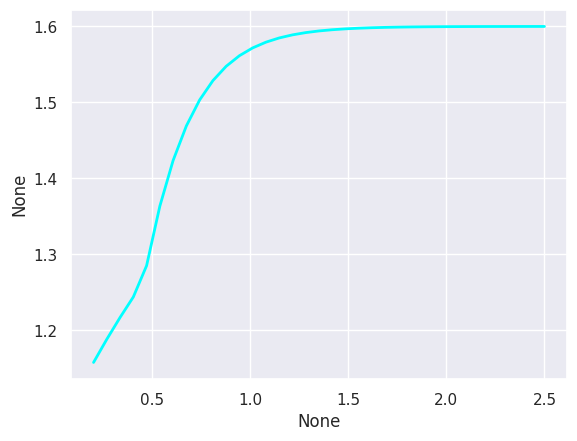

In [8]:
sns.set(style="darkgrid")
sns.lineplot(
    x=true_inputs, y=true_outputs,
    color='cyan',
    linewidth=2
)

In [9]:
class PlainFirstNN(nn.Module):
    
    def __init__(self):
        super().__init__()
        
        self.w00 = nn.Parameter(torch.tensor(0.0), requires_grad=True)
        self.b00 = nn.Parameter(torch.tensor(-0.5), requires_grad=False)

        self.w01 = nn.Parameter(torch.tensor(0.6), requires_grad=False)
        self.b01 = nn.Parameter(torch.tensor(-1.5), requires_grad=False)

        self.w02 = nn.Parameter(torch.tensor(0.0), requires_grad=True)
        self.b02 = nn.Parameter(torch.tensor(0.65), requires_grad=False)

        self.w11 = nn.Parameter(torch.tensor(1.55), requires_grad=False)
        self.w12 = nn.Parameter(torch.tensor(-0.7), requires_grad=False)
        self.w13 = nn.Parameter(torch.tensor(1.22), requires_grad=False)

        self.w20 = nn.Parameter(torch.tensor(0.0), requires_grad=True)
        
    
    def forward(self, input):
        input_to_layer_1 = input * self.w00 + self.b00
        layer_01_output = F.relu(input_to_layer_1)
        layer_01_output = layer_01_output * self.w11
        
        input_to_layer_2 = input * self.w01 + self.b01
        layer_02_output = F.relu(input_to_layer_2)
        layer_02_output = layer_02_output * self.w12
        
        input_to_layer_3 = input * self.w02 + self.b02
        layer_03_output = F.relu(input_to_layer_3)
        layer_03_output = layer_03_output * self.w13
        
        output = layer_01_output + layer_02_output + layer_03_output
        
        output = F.tanh(output)
        output = output * self.w20
        
        return output
    
    

In [11]:
plain_first_model = PlainFirstNN()


In [12]:
pred_outputs = plain_first_model(true_inputs)
pred_outputs

tensor([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], grad_fn=<MulBackward0>)

<Axes: xlabel='None', ylabel='None'>

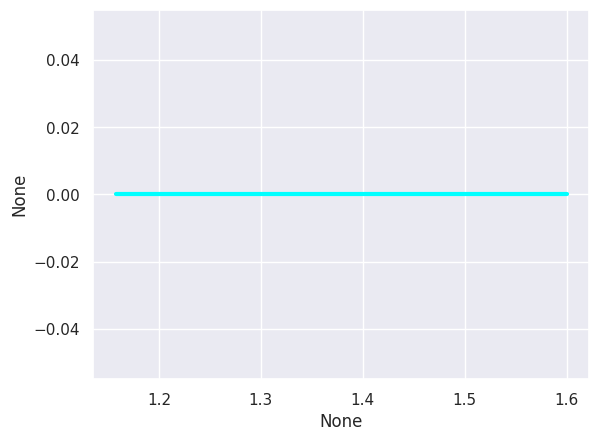

In [14]:
sns.set(style="darkgrid")
sns.lineplot(x=true_outputs, y=pred_outputs.detach(), color = 'cyan', linewidth=3)

In [15]:
optimizer=SGD(plain_first_model.parameters(), lr=0.01)
loss = nn.MSELoss()